In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("/content/games_dataset.csv")

In [ ]:
df

,Game Name,Genre,Platform,Release Year,User Rating
0,Sekiro: Shadows Die Twice,Sports,Nintendo Switch,2014,9.654719
1,Control,Puzzle,Nintendo Switch,2000,3.457386
2,Among Us,Strategy,Nintendo Switch,2007,5.367622
3,Call of Duty: Modern Warfare,Stealth,PlayStation,2005,1.240325
4,League of Legends,Simulation,PC,2021,3.535476
...,...,...,...,...,...
4995,The Legend of Zelda: Breath of the Wild,Sports,PC,2013,6.352838
4996,Assassin's Creed Valhalla,Stealth,Mobile,2020,1.852730
4997,Fall Guys: Ultimate Knockout,Sports,Mobile,2021,5.268067
4998,Borderlands 3,Platformer,Xbox,2018,4.558510


In [ ]:
df.shape

(5000, 6)

In [ ]:
df.isnull().sum()

,0
Game Name,0
Genre,0
Platform,0
Release Year,0
User Rating,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
print(df[(df['User Rating'] < 0) | (df['User Rating'] > 10)])

Empty DataFrame
Columns: [Game Name, Genre, Platform, Release Year, User Rating]
Index: []


In [ ]:
print(df['Release Year'].min())
print(df['Release Year'].max())

2000
2023


Both columns "Genre" and "Platform" both are standardized and dont have any "Unknown" values.

In [ ]:
df["Genre"].value_counts()

,count
Genre,
Sports,403
Puzzle,384
Racing,369
Simulation,368
Role-playing,360
Stealth,360
Horror,356
Strategy,353
Survival,353


In [ ]:
df["Genre"].value_counts().sum()

np.int64(5000)

In [ ]:
df["Platform"].value_counts()

,count
Platform,
PC,1056
Xbox,1009
Nintendo Switch,989
Mobile,986
PlayStation,960


In [ ]:
df["Platform"].value_counts().sum()

np.int64(5000)

Create new features such as 'Decade' from the 'Release Year' column.

In [ ]:
df['Decade'] = (df['Release Year'] // 10)*10

In [ ]:
df

,Game Name,Genre,Platform,Release Year,User Rating,Decade
0,Sekiro: Shadows Die Twice,Sports,Nintendo Switch,2014,9.654719,2010
1,Control,Puzzle,Nintendo Switch,2000,3.457386,2000
2,Among Us,Strategy,Nintendo Switch,2007,5.367622,2000
3,Call of Duty: Modern Warfare,Stealth,PlayStation,2005,1.240325,2000
4,League of Legends,Simulation,PC,2021,3.535476,2020
...,...,...,...,...,...,...
4995,The Legend of Zelda: Breath of the Wild,Sports,PC,2013,6.352838,2010
4996,Assassin's Creed Valhalla,Stealth,Mobile,2020,1.852730,2020
4997,Fall Guys: Ultimate Knockout,Sports,Mobile,2021,5.268067,2020
4998,Borderlands 3,Platformer,Xbox,2018,4.558510,2010


Exploratory Data Analysis (EDA)

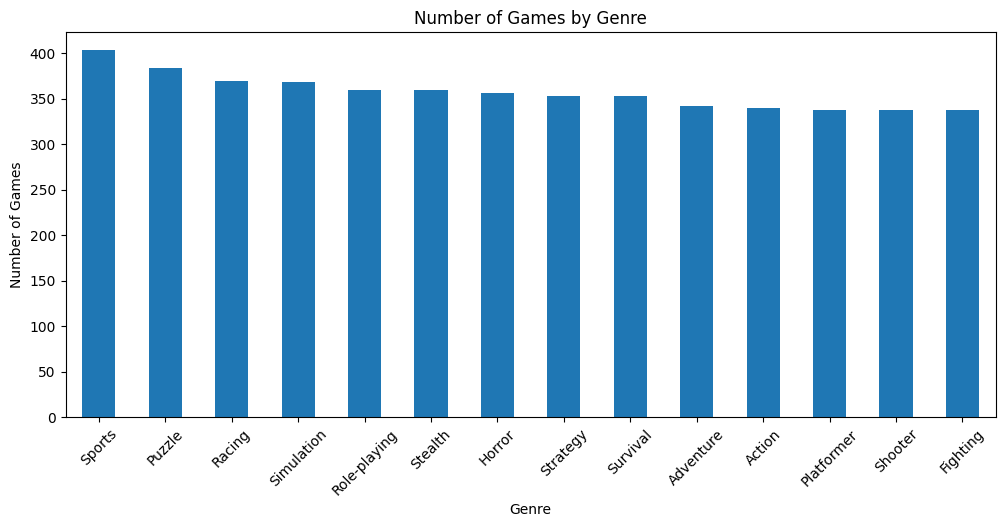

In [ ]:
import matplotlib.pyplot as plt

df['Genre'].value_counts().sort_values(ascending=False).plot(
    kind='bar',
    figsize=(12, 5),
    title='Number of Games by Genre'
)

plt.xlabel('Genre')
plt.ylabel('Number of Games')
plt.xticks(rotation=45)
plt.show()

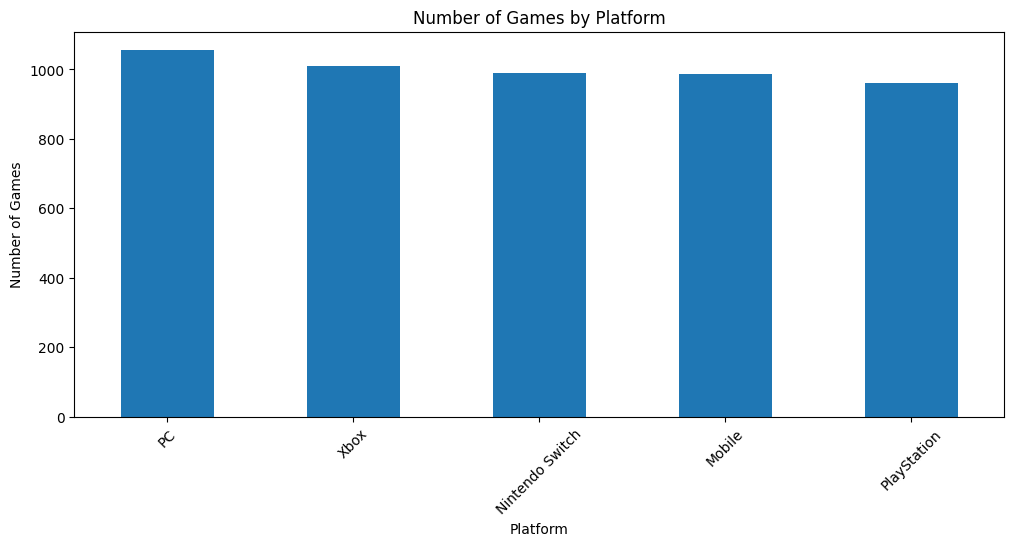

In [ ]:
df['Platform'].value_counts().sort_values(ascending=False).plot(
    kind='bar',
    figsize=(12, 5),
    title='Number of Games by Platform')

plt.xlabel('Platform')
plt.ylabel('Number of Games')
plt.xticks(rotation=45)
plt.show()

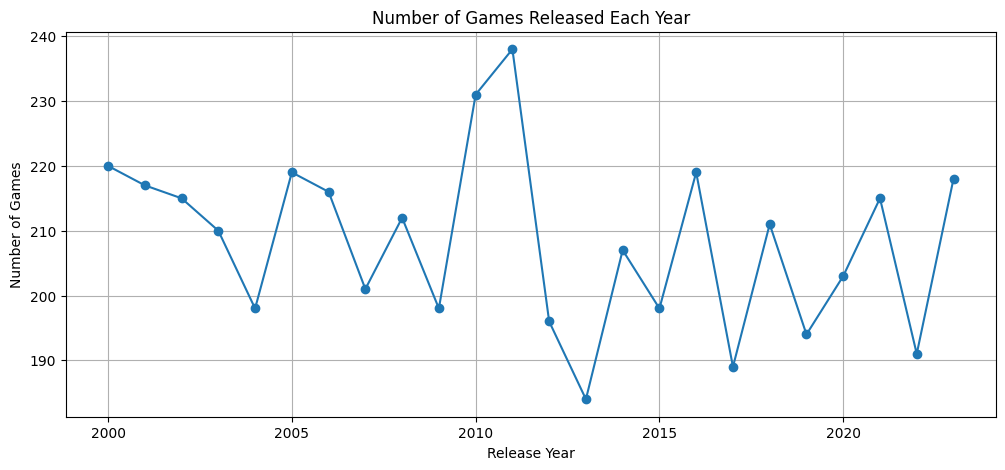

In [ ]:
df['Release Year'].value_counts().sort_index().plot(
    kind='line',
    figsize=(12, 5),
    marker='o',
    title='Number of Games Released Each Year')

plt.xlabel('Release Year')
plt.ylabel('Number of Games')
plt.grid()
plt.show()

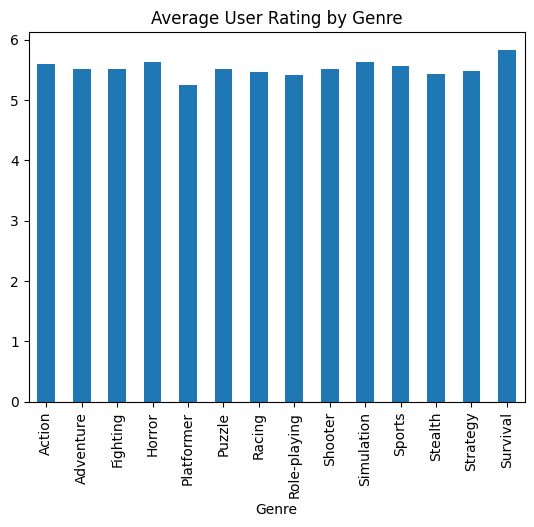

In [ ]:
# Average rating by genre
df.groupby('Genre')['User Rating'].mean().plot(kind='bar')
plt.title('Average User Rating by Genre')
plt.show()

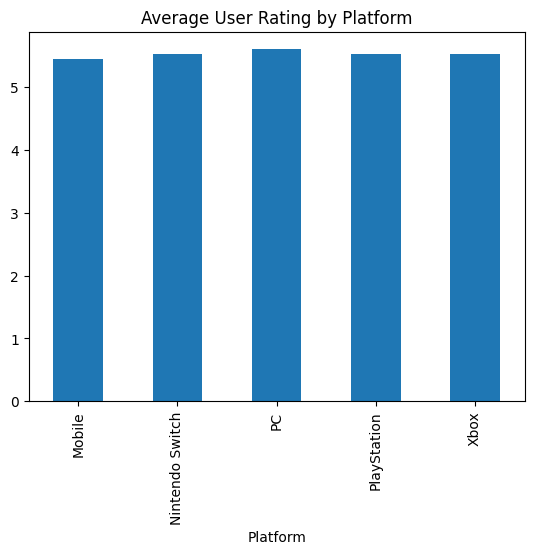

In [ ]:
# Average rating by platform
df.groupby('Platform')['User Rating'].mean().plot(kind='bar')
plt.title('Average User Rating by Platform')
plt.show()

In [ ]:
# Top 5 genres
df.groupby('Genre')['User Rating'].mean().sort_values(ascending=False).head(5)

,User Rating
Genre,
Survival,5.831934
Horror,5.629845
Simulation,5.626343
Action,5.603556
Sports,5.561171


In [ ]:
# Top 5 platforms
df.groupby('Platform')['User Rating'].mean().sort_values(ascending=False).head(5)

,User Rating
Platform,
PC,5.599444
Xbox,5.531032
PlayStation,5.523658
Nintendo Switch,5.523076
Mobile,5.441895


**Advanced Analysis**
- Times Series

In [ ]:
yearly_data = df.groupby('Release Year').agg(
    Game_Releases=('Game Name', 'count'),
    Average_Rating=('User Rating', 'mean'))

yearly_data

,Game_Releases,Average_Rating
Release Year,,
2000,220,5.275934
2001,217,5.519582
2002,215,5.423193
2003,210,5.753535
2004,198,5.906851
2005,219,5.665487
2006,216,5.467574
2007,201,5.047604
2008,212,5.444432


In [ ]:
from statsmodels.tsa.arima.model import ARIMA

Game_Releases        mean    mean_se  mean_ci_lower  mean_ci_upper
2024-01-01     205.761208  13.764914     178.782472     232.739943
2025-01-01     206.511984  13.775497     179.512505     233.511463
2026-01-01     206.465929  13.843737     179.332703     233.599154
2027-01-01     206.468754  13.906773     179.211979     233.725529
2028-01-01     206.468581  13.969818     179.088240     233.848921


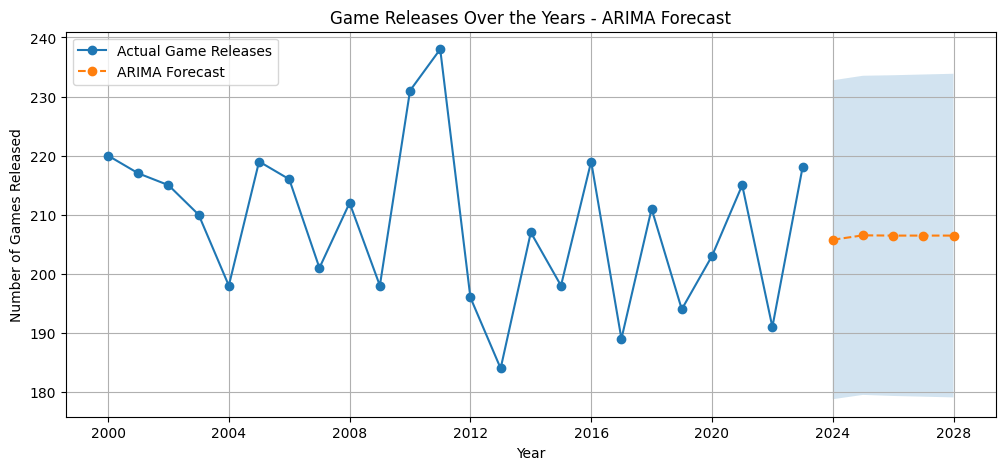

In [ ]:
game_releases = yearly_data['Game_Releases'].copy()

# Converting the index into DateTime format
game_releases.index = pd.to_datetime(
    game_releases.index.astype(str),
    format='%Y')

# Setting the frequency to yearly
game_releases = game_releases.asfreq('YS')

model_releases = ARIMA(game_releases, order=(1, 1, 1))
model_releases_fit = model_releases.fit()

forecast_releases = model_releases_fit.get_forecast(steps=5)
print(forecast_releases.summary_frame())

#Visualizing the Results
plt.figure(figsize=(12, 5))

plt.plot(game_releases.index, game_releases,
         label='Actual Game Releases', marker='o')

plt.plot(forecast_releases.predicted_mean.index,
         forecast_releases.predicted_mean,
         label='ARIMA Forecast', marker='o', linestyle='--')

plt.fill_between(
    forecast_releases.conf_int().index,
    forecast_releases.conf_int().iloc[:, 0],
    forecast_releases.conf_int().iloc[:, 1],
    alpha=0.2)

plt.title('Game Releases Over the Years - ARIMA Forecast')
plt.xlabel('Year')
plt.ylabel('Number of Games Released')
plt.legend()
plt.grid()
plt.show()

Average_Rating      mean   mean_se  mean_ci_lower  mean_ci_upper
2024-01-01      5.304940  0.246868       4.821086       5.788793
2025-01-01      5.279766  0.294512       4.702533       5.856999
2026-01-01      5.296523  0.366432       4.578329       6.014716
2027-01-01      5.285369  0.408168       4.485373       6.085364
2028-01-01      5.292793  0.456866       4.397351       6.188235


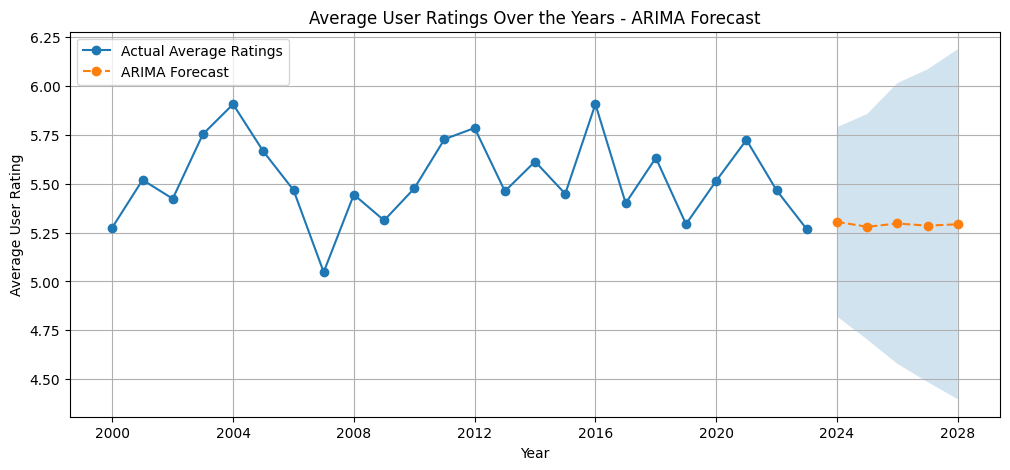

In [ ]:
user_ratings = yearly_data['Average_Rating'].copy()

# Converting the index into DateTime format
user_ratings.index = pd.to_datetime(
    user_ratings.index.astype(str),
    format='%Y')

# Setting the frequency to yearly
user_ratings = user_ratings.asfreq('YS')

model_ratings = ARIMA(user_ratings, order=(1, 1, 1))
model_ratings_fit = model_ratings.fit()

forecast_ratings = model_ratings_fit.get_forecast(steps=5)
print(forecast_ratings.summary_frame())

#Visualizing the Results
plt.figure(figsize=(12, 5))

plt.plot(user_ratings.index, user_ratings,
         label='Actual Average Ratings', marker='o')

plt.plot(forecast_ratings.predicted_mean.index,
         forecast_ratings.predicted_mean,
         label='ARIMA Forecast', marker='o', linestyle='--')

plt.fill_between(
    forecast_ratings.conf_int().index,
    forecast_ratings.conf_int().iloc[:, 0],
    forecast_ratings.conf_int().iloc[:, 1],
    alpha=0.2)

plt.title('Average User Ratings Over the Years - ARIMA Forecast')
plt.xlabel('Year')
plt.ylabel('Average User Rating')
plt.legend()
plt.grid()
plt.show()

        Total_Games  Average_Rating
Decade                             
2000           2106        5.481758
2010           2067        5.581768
2020            827        5.492709


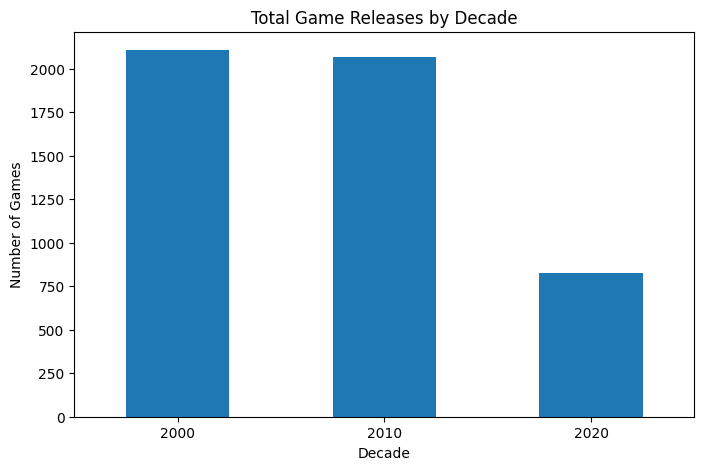

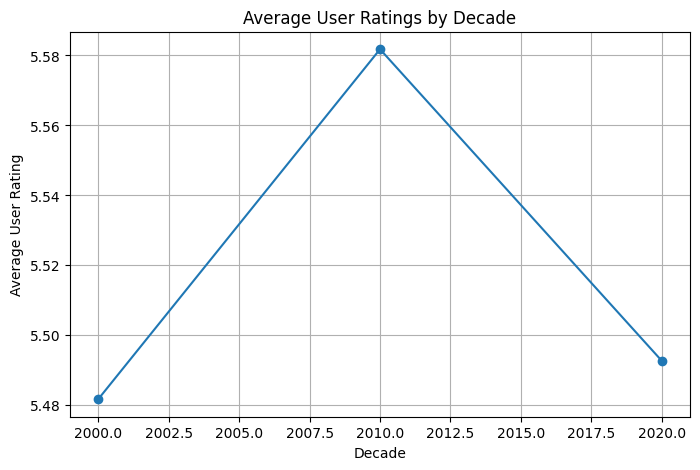

In [ ]:
# Group data by decade
decade_data = df.groupby('Decade').agg(
    Total_Games=('Game Name', 'count'),
    Average_Rating=('User Rating', 'mean'))

print(decade_data)

# Plot game releases by decade
decade_data['Total_Games'].plot(
    kind='bar', figsize=(8, 5), title='Total Game Releases by Decade')

plt.xlabel('Decade')
plt.ylabel('Number of Games')
plt.xticks(rotation=0)
plt.show()

# Plot average ratings by decade
decade_data['Average_Rating'].plot(
    kind='line', marker='o', figsize=(8, 5),
    title='Average User Ratings by Decade')

plt.xlabel('Decade')
plt.ylabel('Average User Rating')
plt.grid()
plt.show()

- Hypothesis Testing

In [ ]:
from scipy.stats import f_oneway

# Group user ratings by platform
platform_groups = []

for platform in df['Platform'].unique():
    ratings = df[df['Platform'] == platform]['User Rating']
    platform_groups.append(ratings)

# Perform One-Way ANOVA test
f_stat, p_value = f_oneway(*platform_groups)

print("F-Statistic:", f_stat)
print("P-Value:", p_value)

# Interpret the result
if p_value < 0.05:
    print("Reject the null hypothesis.")
    print("There is a significant difference in user ratings between platforms.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is no significant difference in user ratings between platforms.")

F-Statistic: 0.47019436417637583
P-Value: 0.7576711463871735
Fail to reject the null hypothesis.
There is no significant difference in user ratings between platforms.


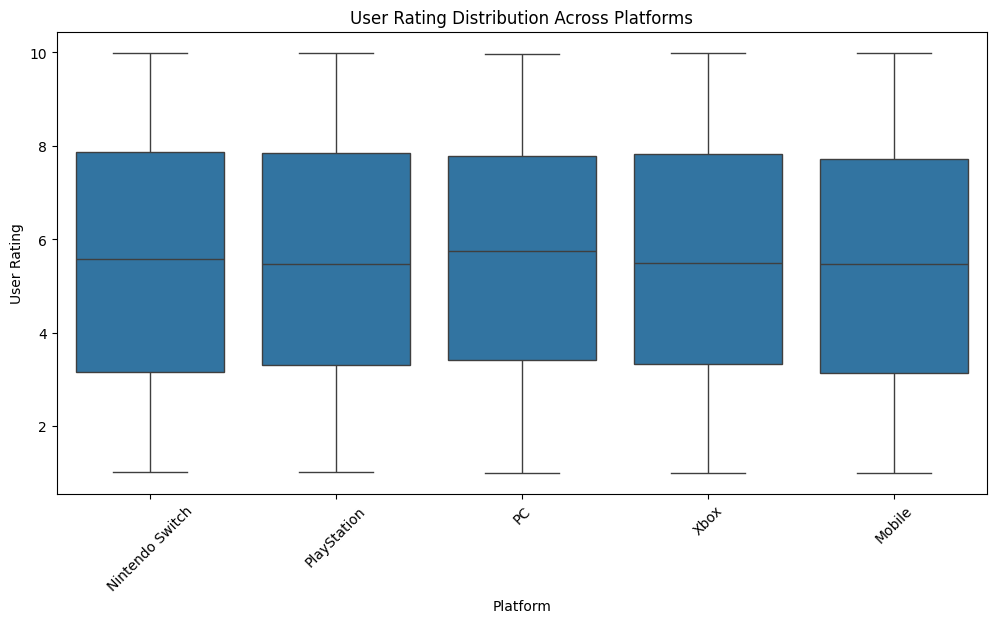

In [ ]:
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Platform', y='User Rating')

plt.title('User Rating Distribution Across Platforms')
plt.xlabel('Platform')
plt.ylabel('User Rating')
plt.xticks(rotation=45)
plt.show()

- Correlation Analysis

In [ ]:
# Calculate correlation
print(df[['Release Year', 'User Rating']].corr())

# Average rating by genre
print("Average Rating by Genre:")
print(df.groupby('Genre')['User Rating'].mean())

# Average rating by platform
print("Average Rating by Platform:")
print(df.groupby('Platform')['User Rating'].mean())

              Release Year  User Rating
Release Year      1.000000     0.000177
User Rating       0.000177     1.000000
Average Rating by Genre:
Genre
Action          5.603556
Adventure       5.510799
Fighting        5.513218
Horror          5.629845
Platformer      5.254660
Puzzle          5.511684
Racing          5.463723
Role-playing    5.412653
Shooter         5.509610
Simulation      5.626343
Sports          5.561171
Stealth         5.423839
Strategy        5.483330
Survival        5.831934
Name: User Rating, dtype: float64
Average Rating by Platform:
Platform
Mobile             5.441895
Nintendo Switch    5.523076
PC                 5.599444
PlayStation        5.523658
Xbox               5.531032
Name: User Rating, dtype: float64


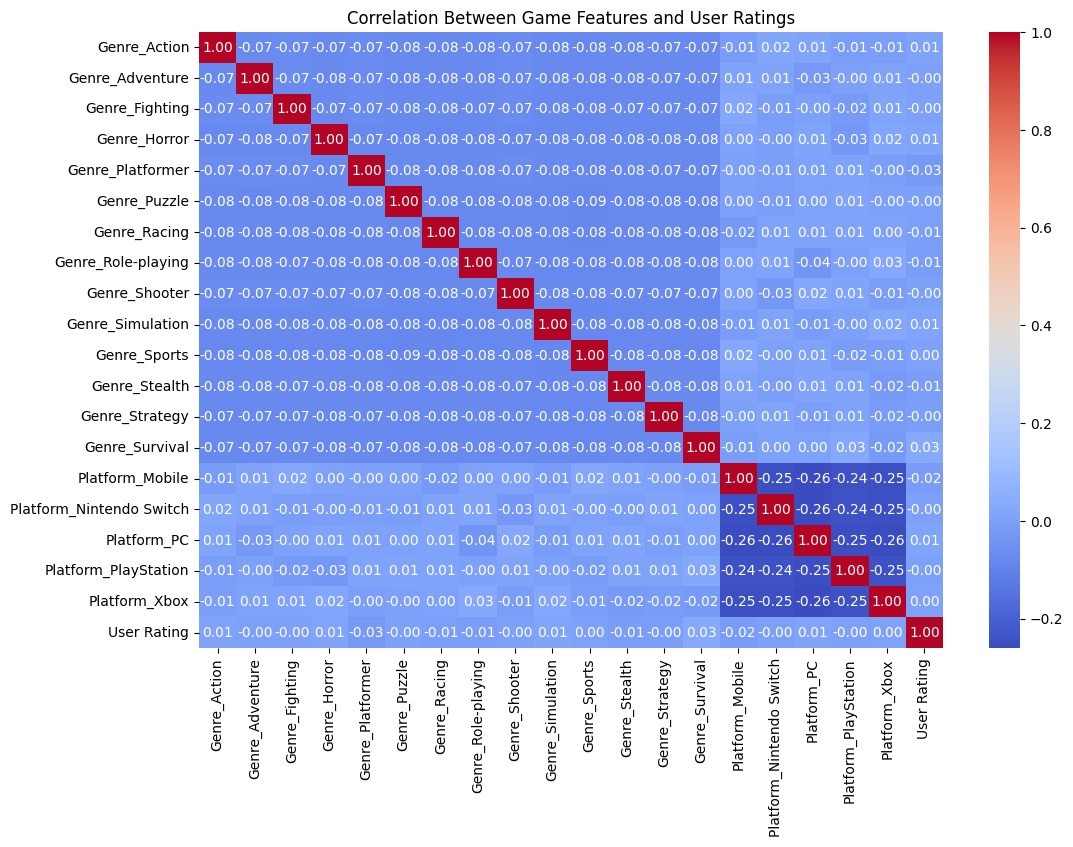

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    encoded_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f')

plt.title('Correlation Between Game Features and User Ratings')
plt.show()

**Machine Learning**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

In [ ]:
X = df[['Genre', 'Platform', 'Release Year']]
y = df['User Rating']

In [ ]:
X = pd.get_dummies(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R2 Score:", r2_score(y_test, predictions))

Mean Absolute Error: 2.42552519332395
R2 Score: -0.2568400946761189


Release Year                0.413552
Platform_Xbox               0.049385
Platform_Nintendo Switch    0.048288
Platform_PlayStation        0.044179
Platform_Mobile             0.042710
Platform_PC                 0.042043
Genre_Shooter               0.029166
Genre_Adventure             0.029009
Genre_Stealth               0.028373
Genre_Racing                0.027289
dtype: float64


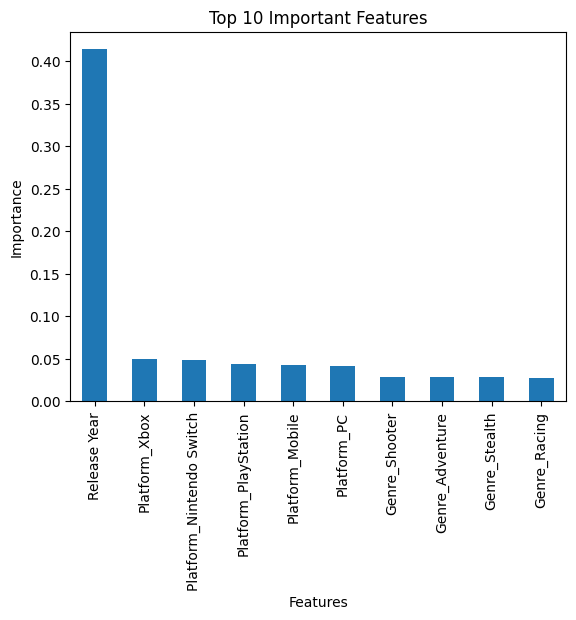

In [ ]:
# Most important feature
importance = pd.Series(
    model.feature_importances_,
    index=X.columns)

print(importance.sort_values(ascending=False).head(10))

# Plot the top 10 features
importance.sort_values(ascending=False).head(10).plot(kind='bar')
plt.title('Top 10 Important Features')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()